# Visualisation Tools for ECG Signals

In this notebook, I developed a series of tools for visualising ECG signals. 

### Using WFDB to Read Signal Data
The documentation for WFDB is available here: https://wfdb.readthedocs.io/en/latest/

In [5]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

#### Plotting each Signal in a Directory
Press enter to create the plot of each sequential signal in the directory.  

In [ ]:
wfdb.plot.plot_all_records('physionet2017/training2017')

#### Plotting an Individual Signal

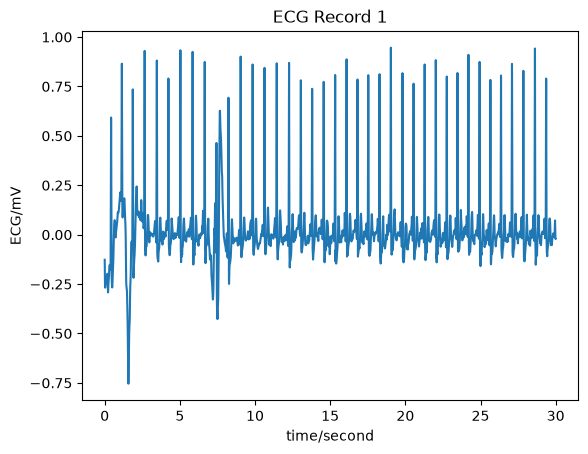

In [ ]:
def plot_signal(signal_number):
    record = wfdb.rdrecord(f'physionet2017/training2017/A{signal_number:05d}') # Read the record

    wfdb.plot_wfdb(record=record,  
                   title=f'ECG Record {signal_number}', 
                   time_units='seconds'


#### Annotating an ECG Plot - Peaks

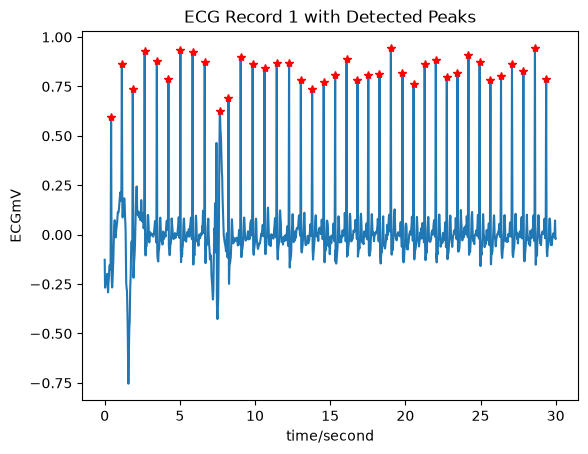

In [2]:
record = wfdb.rdrecord('physionet2017/training2017/A00001') # Read the record

sig = record.p_signal[:, 0]  # Get the first channel of the signal
peaks, _ = find_peaks(record.p_signal[:, 0], height=0.5, distance=100)

ann = wfdb.Annotation(record_name='physionet2017/training2017/A00001',
                      extension='qrs', 
                      sample=peaks,
                      symbol=['N'] * len(peaks),
                      chan=np.zeros(len(peaks), dtype=int),
                      fs=record.fs)

wfdb.plot_wfdb(record=record, annotation=ann, title='ECG Record 1 with Detected Peaks', time_units='seconds')

#### Annotating an ECG Plot - Troughs

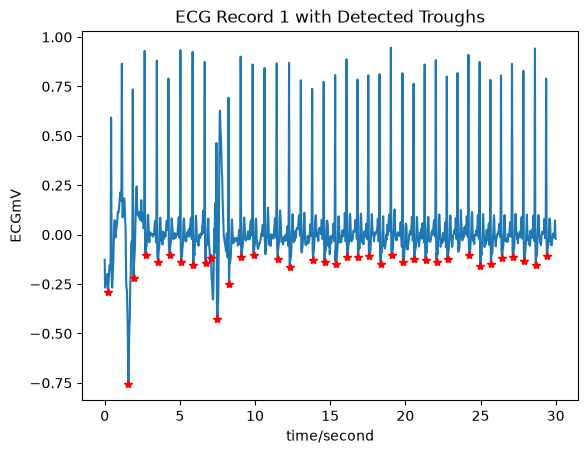

In [11]:
record = wfdb.rdrecord('physionet2017/training2017/A00001') # Read the record

sig = record.p_signal[:, 0]  # Get the first channel of the signal
troughs, _ = find_peaks(-record.p_signal[:, 0], height=0.1, distance=100)

ann = wfdb.Annotation(record_name='physionet2017/training2017/A00001',
                      extension='qrs', 
                      sample=troughs,
                      symbol=['N'] * len(troughs),
                      chan=np.zeros(len(troughs), dtype=int),
                      fs=record.fs)

wfdb.plot_wfdb(record=record, annotation=ann, title='ECG Record 1 with Detected Troughs', time_units='seconds')

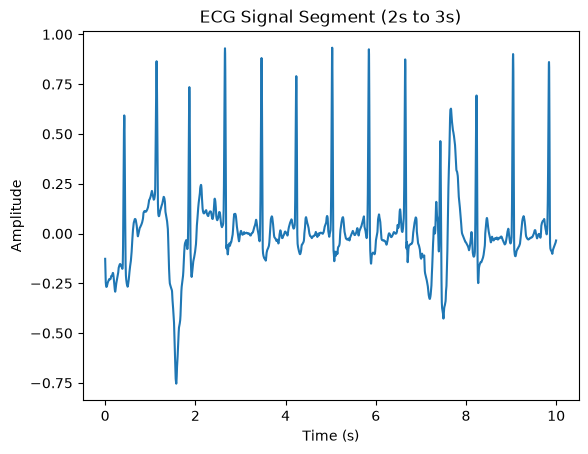

In [9]:
record = wfdb.rdrecord('physionet2017/training2017/A00001') # Read the record

fs = record.fs # Sampling frequency
signal = record.p_signal[:, 0] # Get the first channel of the signal

t1, t2 = 0, 10
segment = signal[int(t1*fs):int(t2*fs)]
time = np.arange(len(segment)) / fs + t1

plt.plot(time, segment)
plt.title('ECG Signal Segment (2s to 3s)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

## To Do - NO CLAUDE

#### **Peak to Peak Region**
Develop code which allows you to zoom in on a single pulse. 

#### **QRS Detection**
The first step is to create some code which can detect the various points of the sinus rhythm. This will require peak and trough detection relative to the previous point. 

#### **Frequency Domain Analysis**
Look into how to extract the frequency spectrum from the training samples. 